In [2]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
import seaborn as sns

In [5]:
df=pd.read_csv("C:/Users/ELCOT/Downloads/hotel_bookings.csv/hotel_bookings.csv")

In [6]:
df.head

<bound method NDFrame.head of                hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   


In [7]:
df.tail

<bound method NDFrame.tail of                hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   


In [8]:
df.shape

(119390, 32)

In [9]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [10]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [11]:
df.dtypes


hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [12]:
df['company'] = df['company'].fillna(df['company'].mean())

In [13]:
df.isnull().sum()

hotel                                 0
is_canceled                           0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             488
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             16340
company                               0


In [14]:
df['country']=df['country'].fillna(df['country'].mode()[0])

In [15]:
df['children'] = df['children'].fillna(df['children'].mean())

In [16]:
df['agent'] = df['agent'].fillna(df['agent'].mean())

In [17]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [18]:
df_encoded = pd.get_dummies(
    df,
    columns=['hotel', 'meal', 'customer_type'],
    drop_first=True,
    dtype=int
)

In [19]:
df_encoded.head()

,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,reservation_status,reservation_status_date,hotel_Resort Hotel,meal_FB,meal_HB,meal_SC,meal_Undefined,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,0,342,2015,July,27,1,0,0,2,0.0,...,Check-Out,2015-07-01,1,0,0,0,0,0,1,0
1,0,737,2015,July,27,1,0,0,2,0.0,...,Check-Out,2015-07-01,1,0,0,0,0,0,1,0
2,0,7,2015,July,27,1,0,1,1,0.0,...,Check-Out,2015-07-02,1,0,0,0,0,0,1,0
3,0,13,2015,July,27,1,0,1,1,0.0,...,Check-Out,2015-07-02,1,0,0,0,0,0,1,0
4,0,14,2015,July,27,1,0,2,2,0.0,...,Check-Out,2015-07-03,1,0,0,0,0,0,1,0


In [20]:
numeric_cols = [
    'lead_time',
    'adr',
    'stays_in_week_nights',
    'adults',
    'children'
]

df[numeric_cols].head()

,lead_time,adr,stays_in_week_nights,adults,children
0,342,0.0,0,2,0.0
1,737,0.0,0,2,0.0
2,7,75.0,1,1,0.0
3,13,75.0,1,1,0.0
4,14,98.0,2,2,0.0


In [21]:
df[numeric_cols].describe()

,lead_time,adr,stays_in_week_nights,adults,children
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,104.011416,101.831122,2.500302,1.856403,0.103890
std,106.863097,50.535790,1.908286,0.579261,0.398555
min,0.000000,-6.380000,0.000000,0.000000,0.000000
25%,18.000000,69.290000,1.000000,2.000000,0.000000
50%,69.000000,94.575000,2.000000,2.000000,0.000000
75%,160.000000,126.000000,3.000000,2.000000,0.000000
max,737.000000,5400.000000,50.000000,55.000000,10.000000


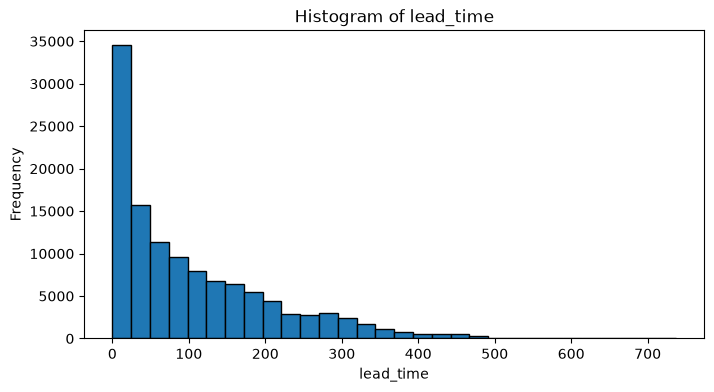

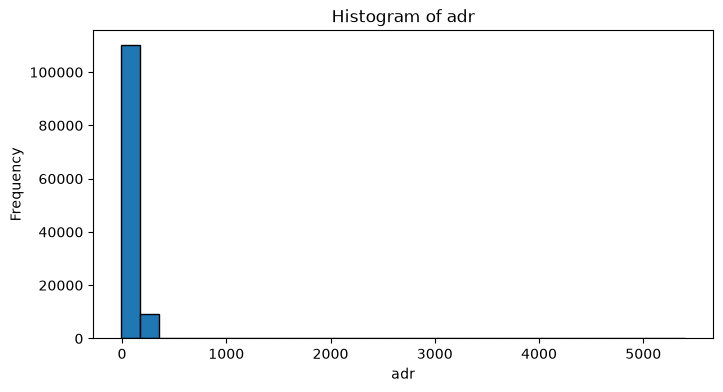

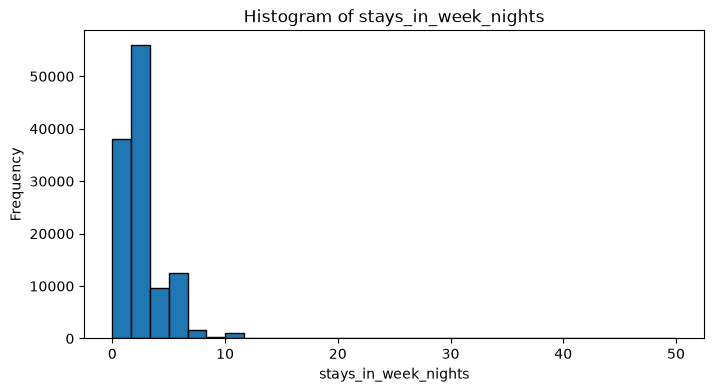

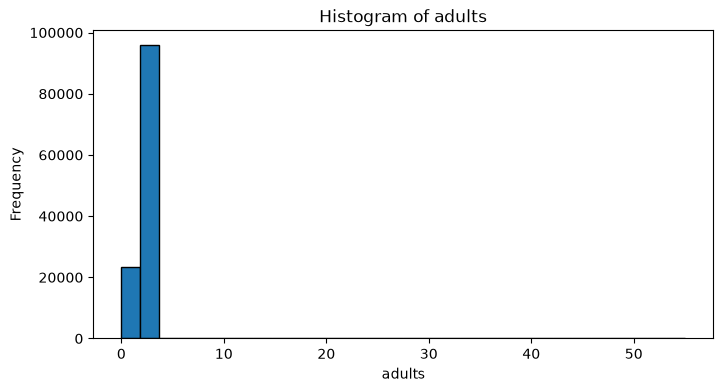

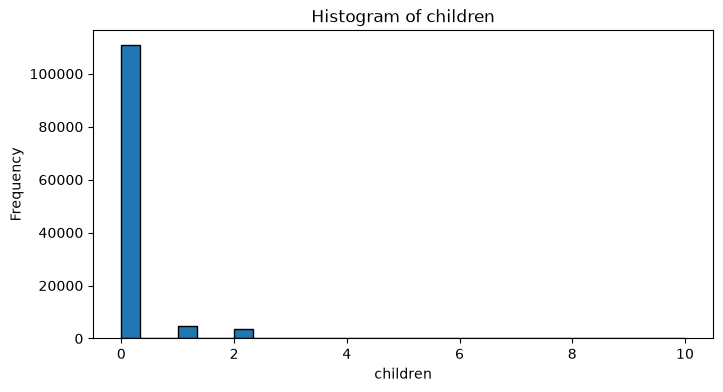

In [31]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.title('Histogram of ' + col)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

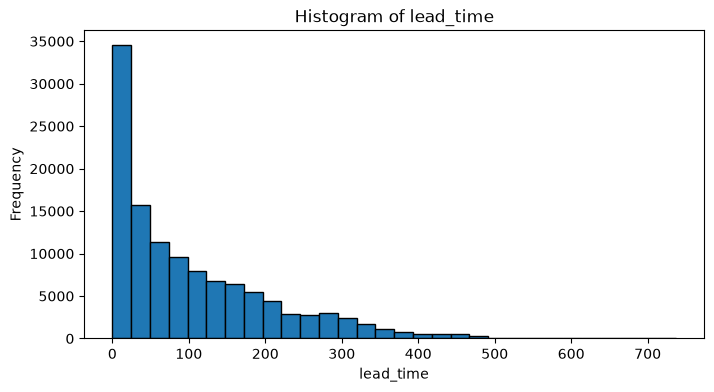

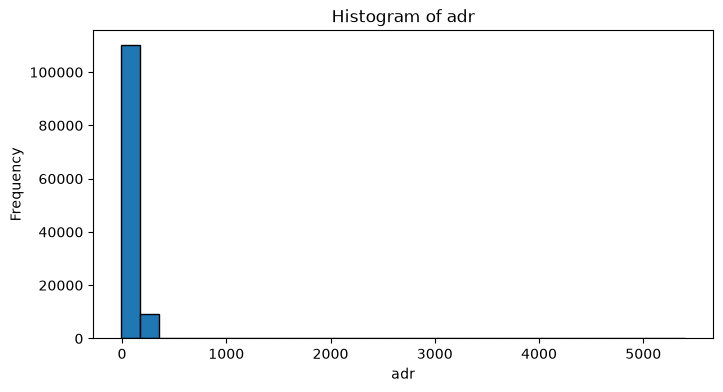

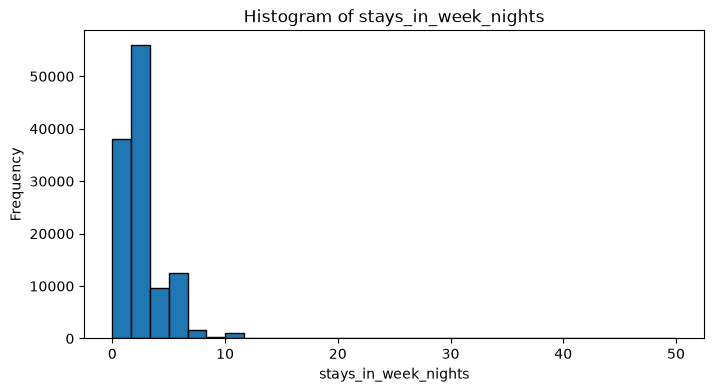

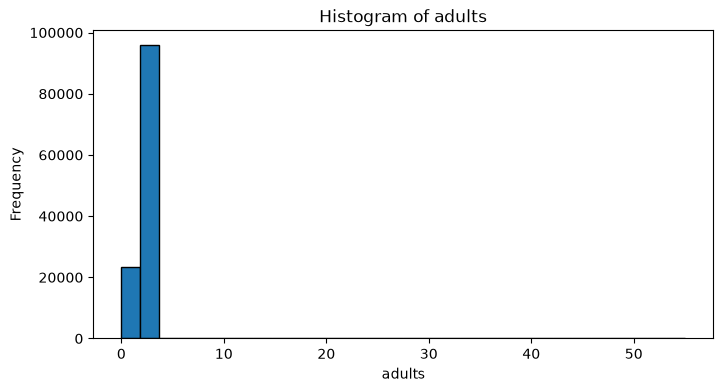

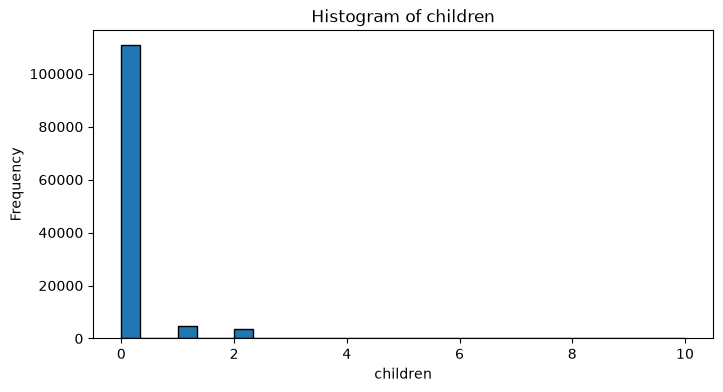

In [26]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.title('Histogram of ' + col)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

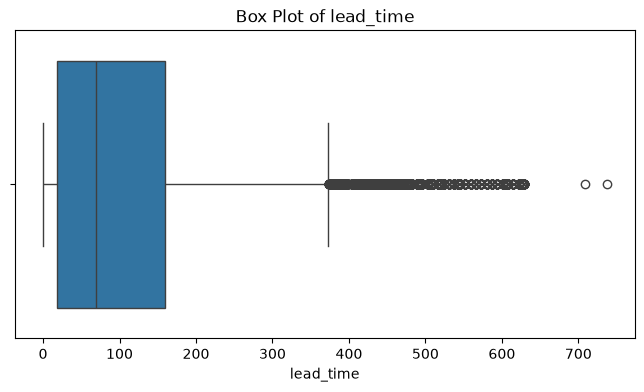

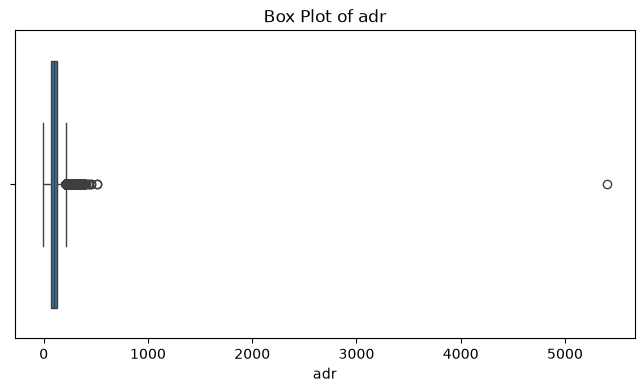

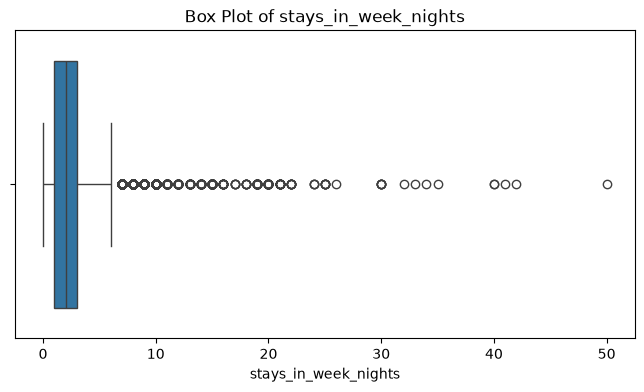

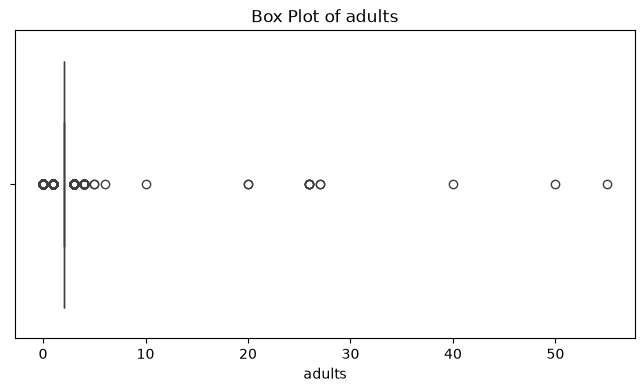

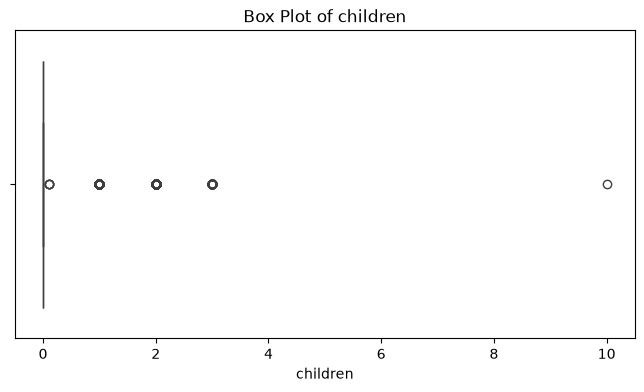

In [27]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title('Box Plot of ' + col)
    plt.xlabel(col)
    plt.show()

In [28]:
for col in numeric_cols:
    print(col, "Kurtosis:", df[col].kurt())

lead_time Kurtosis: 1.696448848558546
adr Kurtosis: 1013.1898508588181
stays_in_week_nights Kurtosis: 24.28455481541732
adults Kurtosis: 1352.1151163093718
children Kurtosis: 18.674418509585312


In [29]:
for col in numeric_cols:
    print(col, "Kurtosis:", df[col].kurt())

lead_time Kurtosis: 1.696448848558546
adr Kurtosis: 1013.1898508588181
stays_in_week_nights Kurtosis: 24.28455481541732
adults Kurtosis: 1352.1151163093718
children Kurtosis: 18.674418509585312


In [30]:
for col in numeric_cols:
    skew = df[col].skew()

    if skew > 0.5:
        result = "Positively Skewed"
    elif skew < -0.5:
        result = "Negatively Skewed"
    else:
        result = "Approximately Symmetric"

    print(col, ":", result)

lead_time : Positively Skewed
adr : Positively Skewed
stays_in_week_nights : Positively Skewed
adults : Positively Skewed
children : Positively Skewed
